# A small mixture-of-experts transformer

This notebook follows a token through a router, two selected experts, and a
weighted output. It then trains a tiny GPT on a repeated Russian passage.
Use the project's MLX environment on Apple Silicon with the analysis extra
installed. Paths detect the repository root.

Our implementation lives in `src/llm_training/models/moe_mlx.py`. The first
version uses ordinary parameterization, four bias-free GELU experts per
feed-forward layer, top-2 token routing, and a balancing loss. Every token keeps
its selected experts. The router works on each position’s hidden vector.

## Where the experts go

A dense block performs attention, then one feed-forward network. A MoE block
replaces that feed-forward network with several alternatives. The attention and
residual connections remain in the block. Each layer owns its own router and
expert weights. “Expert” names a learned network, not an assigned subject such as
math or grammar.

For each token vector x, the router produces E scores. We select k experts,
normalize their selected scores with softmax, run those experts, and add their
outputs using the resulting weights. Here E = 4 and k = 2.

In [1]:
from pathlib import Path
import sys
import math
import tempfile
import random

import matplotlib.pyplot as plt
import numpy as np
import mlx.core as mx
import mlx.nn as nn
import mlx.optimizers as optim
from mlx.utils import tree_flatten
from tokenizers import Tokenizer

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(root / "src"))
from llm_training.models.config import GPTConfig
from llm_training.models.gpt_mlx import GPT
from llm_training.models.moe_mlx import SparseMoE, route_tokens
from llm_training.pretraining_mlx.data import get_batch
from llm_training.pretraining_mlx.train import TrainConfig, make_loss_and_grad, make_optimizer, learning_rate_at_step

mx.set_default_device(mx.gpu)
mx.random.seed(42)

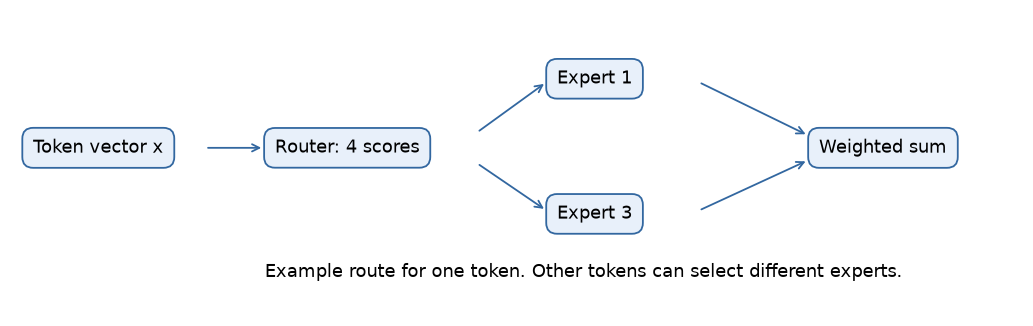

In [2]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.axis("off")
boxes = [(0.02, .55, "Token vector x"), (.26, .55, "Router: 4 scores"),
         (.54, .78, "Expert 1"), (.54, .33, "Expert 3"),
         (.80, .55, "Weighted sum")]
for x, y, text in boxes:
    ax.text(x, y, text, transform=ax.transAxes, ha="left", va="center",
            bbox=dict(boxstyle="round,pad=.6", fc="#e8f0fa", ec="#3267a0"))
for start, end in [((.19,.55),(.25,.55)), ((.46,.6),(.53,.77)),
                   ((.46,.5),(.53,.34)), ((.68,.77),(.79,.59)),
                   ((.68,.34),(.79,.51))]:
    ax.annotate("", xy=end, xytext=start, xycoords="axes fraction",
                arrowprops=dict(arrowstyle="->", color="#3267a0"))
ax.text(.25,.12,"Example route for one token. Other tokens can select different experts.",
        transform=ax.transAxes)
plt.show()

## 0. Build the layer from ordinary neural-network pieces

### What does the router see?

At each token position, attention has already mixed information from earlier
positions into a hidden vector. Our block passes `x = ln2(residual_stream)`
to the MoE. Its shape is `[batch, positions, d_model]`. Here **activations**
means those current hidden values, not just an activation function such as GELU.

Each token gets its own route. The same word can take different routes in
different contexts or layers. The router receives the whole hidden vector;
it does not look up a fixed expert for a token ID.

### First, one expert is just a feed-forward network

The next code cell computes the up projection, GELU activation, and down
projection explicitly, and prints their shapes.

`W_up` and `W_down` are learned parameters. GELU has no learned parameters:
it applies `GELU(u) = u × Φ(u)` elementwise, with Φ the standard-normal CDF.
The nonlinearity matters: without it, the two matrices could be collapsed into
one linear transformation. Our experts omit biases.

We will create four independent copies by putting their matrices in banks
`W_up[E, h, d]` and `W_down[E, d, h]`. These are dense matrices. The network
becomes sparse in **which experts execute for each token**, rather than by
forcing individual matrix entries to zero.

In [3]:
# Tiny, inspectable dimensions: three token activations, four experts.
# NumPy's local RNG keeps the later training example's MLX seed unchanged.
toy_rng = np.random.default_rng(17)
toy_x = mx.array([[1., 0., .5, -.5],
                  [-1., 0., .5, -.5],
                  [0., 1., -.5, .5]])          # [N=3, d=4]
toy_up = mx.array(toy_rng.normal(0, .4, (4, 6, 4)).astype('float32'))
toy_down = mx.array(toy_rng.normal(0, .4, (4, 4, 6)).astype('float32'))
toy_expert = 0
toy_u = toy_x @ toy_up[toy_expert].T             # [3, 6]
toy_a = nn.gelu(toy_u)
toy_y = toy_a @ toy_down[toy_expert].T           # [3, 4]
print('Input activations:\n', np.array(toy_x))
print('One expert: input → up projection → GELU → down projection')
print(toy_x.shape, '→', toy_u.shape, '→', toy_a.shape, '→', toy_y.shape)
print('First token before GELU:', np.round(np.array(toy_u[0]), 3))
print('First token after GELU: ', np.round(np.array(toy_a[0]), 3))

Input activations:
 [[ 1.   0.   0.5 -0.5]
 [-1.   0.   0.5 -0.5]
 [ 0.   1.  -0.5  0.5]]
One expert: input → up projection → GELU → down projection
(3, 4) → (3, 6) → (3, 6) → (3, 4)
First token before GELU: [ 0.585 -0.746 -0.729 -0.598  0.654  0.38 ]
First token after GELU:  [ 0.421 -0.17  -0.17  -0.164  0.486  0.246]


### A router is another learned linear layer

For each expert `e`, the router has a learned vector `r_e` of length `d`.
Its score is the dot product `score_e = sum_j(x_j × r_ej)`.
A large positive score means the current activations align with that expert's
router vector. This is a learned preference, not a human-written rule about
language or token type. There is no GELU in our router.

The next code cell calculates these scores, selects expert indices, gathers
the selected scores, and computes their normalized gates using MLX operations.

Softmax preserves ordering, so selecting the largest scores selects the same
experts as selecting the largest probabilities. With top-2 we renormalize over
**only those two scores**. Equivalently, divide their full-softmax probabilities
by their sum. The resulting two gates sum to one.

Below, we hand-set router vectors so you can predict the choice: expert 0
responds to positive feature 0, expert 1 to negative feature 0, expert 2 to
positive feature 1, and expert 3 to negative feature 1. Training normally learns
these vectors from random initialization; hidden features are also learned.

In [4]:
toy_router = mx.array([[2., 0., 0., 0.],
                       [-2., 0., 0., 0.],
                       [0., 2., 0., 0.],
                       [0., -2., 0., 0.]])
toy_scores = toy_x @ toy_router.T
toy_probabilities = mx.softmax(toy_scores, axis=-1)
# A sorted selection is easiest to read. Production argpartition returns
# the same selected set, without promising an order within that set.
toy_ids = mx.stop_gradient(mx.argsort(-toy_scores, axis=-1)[:, :2])
toy_selected_scores = mx.take_along_axis(toy_scores, toy_ids, axis=-1)
toy_gates = mx.softmax(toy_selected_scores, axis=-1)
toy_selected_probabilities = mx.take_along_axis(toy_probabilities, toy_ids, axis=-1)
np.testing.assert_allclose(np.array(toy_gates),
    np.array(toy_selected_probabilities / toy_selected_probabilities.sum(-1, keepdims=True)), atol=1e-6)
print('Router scores, rows=tokens, columns=experts:\n', np.array(toy_scores))
print('All-expert probabilities:\n', np.round(np.array(toy_probabilities), 3))
print('Selected expert IDs:\n', np.array(toy_ids))
print('Renormalized selected gates:\n', np.round(np.array(toy_gates), 3))
print('A tied runner-up can be any of the tied experts.')

Router scores, rows=tokens, columns=experts:
 [[ 2. -2.  0.  0.]
 [-2.  2.  0.  0.]
 [ 0.  0.  2. -2.]]
All-expert probabilities:
 [[0.776 0.014 0.105 0.105]
 [0.014 0.776 0.105 0.105]
 [0.105 0.105 0.776 0.014]]
Selected expert IDs:
 [[0 2]
 [1 2]
 [2 0]]
Renormalized selected gates:
 [[0.881 0.119]
 [0.881 0.119]
 [0.881 0.119]]
A tied runner-up can be any of the tied experts.


### Dispatch tokens, run selected FFNs, then combine

A literal implementation uses a loop over tokens and their chosen experts.
Only two FFNs run per token. Expert 0 can process many tokens and expert 3
can process none; no weights are created or removed during routing.

If a token chooses experts 0 and 2 with gates 0.8 and 0.2, its MoE output is
`0.8 × FFN_0(x) + 0.2 × FFN_2(x)`. Each FFN returns a full `d`-feature vector.
We sum those vectors, rather than assigning different feature slices to experts.
The transformer then adds this output to its residual stream.

In [5]:
def toy_ffn(x, expert):
    return nn.gelu(x @ toy_up[expert].T) @ toy_down[expert].T

toy_rows = []
for token in range(toy_x.shape[0]):
    combined = mx.zeros((4,))
    for slot in range(2):
        expert = int(toy_ids[token, slot].item())
        contribution = toy_gates[token, slot] * toy_ffn(toy_x[token], expert)
        combined = combined + contribution
        print(f'token {token} → expert {expert}, gate={toy_gates[token, slot].item():.3f}')
    toy_rows.append(combined)
toy_combined = mx.stack(toy_rows)
print('Combined output shape:', toy_combined.shape)
print('First token output:', np.round(np.array(toy_combined[0]), 4))

token 0 → expert 0, gate=0.881
token 0 → expert 2, gate=0.119
token 1 → expert 1, gate=0.881
token 1 → expert 2, gate=0.119
token 2 → expert 2, gate=0.881
token 2 → expert 0, gate=0.119
Combined output shape: (3, 4)
First token output: [0.0789 0.0388 0.4281 0.3445]


### How can a hard choice be learned?

`top_k` returns integer indices. We do not differentiate through a change in
those indices. For the current selected set, however, the two gate weights are
smooth functions of the selected scores. Backpropagation follows:

Gradients flow from the language-model loss through the weighted expert
outputs, selected gates, and selected router scores to the router weights
and the input hidden vector.

The selected experts also receive gradients through their ordinary linear
layers and GELU. An unselected expert receives no task gradient from that token.
A router update can change score ordering, so a future forward pass can select
a different expert. We do not need a derivative of the discrete ordering itself.

For two selected experts, changing one score changes both normalized gates.
If their output vectors are `y_i`, gates `g_i`, and mixture `y`, then
`∂y / ∂score_i = g_i × (y_i − y)` while the selected set stays fixed.
Thus the task loss learns which selected output helps more. Initially the
experts are random networks; useful specialization can emerge through joint
training. Expert numbers do not come with predefined meanings.

Here we differentiate a tiny squared-error objective through the gates.
The expert outputs are held fixed so we can inspect just the routing part.
Unselected scores have zero **task** gradient for our normalized top-2 gates.
The balancing loss later in the notebook also uses full-router probabilities,
so it can update scores outside the selected set.

In [6]:
# Evaluate all experts here only to make the gradient example easy to inspect.
toy_all_outputs = mx.stack([toy_ffn(toy_x, e) for e in range(4)], axis=1)  # [N, E, d]
toy_target = mx.ones_like(toy_x) * .25

def toy_routing_objective(scores):
    ids, gates, _ = route_tokens(scores, 2)
    outputs = mx.take_along_axis(toy_all_outputs, ids[..., None], axis=1)
    prediction = mx.sum(gates[..., None] * outputs, axis=1)
    return mx.mean((prediction - toy_target) ** 2)

toy_score_grad = mx.grad(toy_routing_objective)(toy_scores)
toy_production_ids, _, _ = route_tokens(toy_scores, 2)
toy_selected_mask = mx.any(toy_production_ids[..., None] == mx.arange(4), axis=1)
assert mx.all(mx.where(toy_selected_mask, True, toy_score_grad == 0)).item()
assert mx.linalg.norm(toy_score_grad).item() > 0
print('Task gradient for each router score:\n', np.round(np.array(toy_score_grad), 6))
# Since scores = x @ W_router.T, the chain rule gives:
toy_router_grad = toy_score_grad.T @ toy_x
print('Gradient of router weight matrix:\n', np.round(np.array(toy_router_grad), 6))
print('An SGD step would set W_router ← W_router − learning_rate × this gradient.')

Task gradient for each router score:
 [[ 0.000883  0.       -0.000883  0.      ]
 [ 0.       -0.000405  0.000405  0.      ]
 [-0.010992  0.        0.010992  0.      ]]
Gradient of router weight matrix:
 [[ 0.000883 -0.010992  0.005937 -0.005937]
 [ 0.000405  0.       -0.000202  0.000202]
 [-0.001287  0.010992 -0.005735  0.005735]
 [ 0.        0.        0.        0.      ]]
An SGD step would set W_router ← W_router − learning_rate × this gradient.


## 1. Routing scores and selected gates

The scores below are an illustrative router output for four tokens.
Our production router calculates them as `x @ router.weight.T`.
Rows are tokens, columns are experts. Only the two highest-scoring experts in
each row contribute to the output. The selected weights sum to one.

The expert indices are discrete choices. We stop gradients through the indices
and differentiate through the selected scores and gates.

Selected expert indices (zero-based):
[[0 3]
 [2 1]
 [1 2]
 [3 2]]
Selected weights:
[[0.731 0.269]
 [0.731 0.269]
 [0.881 0.119]
 [0.953 0.047]]


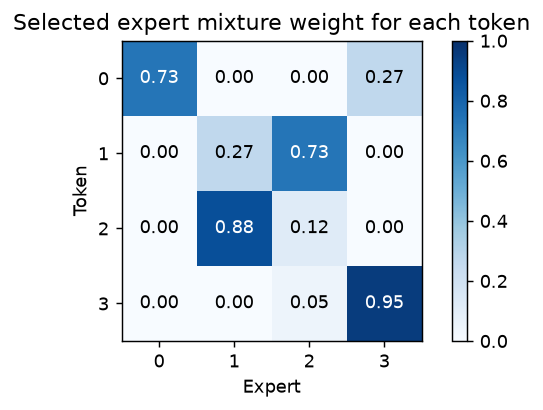

In [7]:
logits = mx.array([[3., 1., -1., 2.], [-2., 2., 3., 0.],
                   [1., 4., 2., -1.], [0., 1., 2., 5.]])
indices, gates, diagnostics = route_tokens(logits, 2)
print("Selected expert indices (zero-based):")
print(np.array(indices))
print("Selected weights:")
print(np.round(np.array(gates), 3))
assert np.allclose(np.array(gates.sum(-1)), 1)
weights = np.zeros((4, 4))
for token in range(4):
    weights[token, np.array(indices[token])] = np.array(gates[token])
fig, ax = plt.subplots(figsize=(6, 3))
image = ax.imshow(weights, vmin=0, vmax=1, cmap="Blues")
for (token, expert), value in np.ndenumerate(weights):
    ax.text(expert, token, f"{value:.2f}", ha="center", va="center",
            color="white" if value > .6 else "black")
ax.set(xlabel="Expert", ylabel="Token", xticks=range(4), yticks=range(4),
       title="Selected expert mixture weight for each token")
fig.colorbar(image, ax=ax)
plt.show()

## 2. Expert computation and combination

Each expert is a feed-forward network `d → h → GELU → d`.
Different experts have separate matrices. We use `gather_mm` to apply the
selected matrices to token slots. This computes the selected expert paths
without a Python loop over tokens or a variable-shaped token queue.

The explicit reference below evaluates all experts and then applies the gates.
It is easy to inspect. The trainable implementation computes selected expert
slots using gathered matrix multiplies. Both should produce the same output.

In [8]:
expert_config = GPTConfig(vocab_size=16, d_model=8, num_experts=4,
                          experts_per_token=2, expert_hidden_dim=16)
moe = SparseMoE(expert_config)
vectors = mx.random.normal((6, 8))
actual, routing = moe(vectors)
chosen, mixture, _ = route_tokens(moe.router(vectors), 2)
reference = mx.zeros_like(vectors)
for expert in range(4):
    hidden = moe.activation(vectors @ moe.up.weight[expert].T)
    expert_output = hidden @ moe.down.weight[expert].T
    gate = mx.sum((chosen == expert) * mixture, axis=-1)
    reference = reference + gate[:, None] * expert_output
np.testing.assert_allclose(np.array(actual), np.array(reference), atol=1e-5, rtol=1e-4)
print("Input and output shapes:", vectors.shape, actual.shape)
print("Selected-expert output matches the explicit weighted reference.")

Input and output shapes: (6, 8) (6, 8)
Selected-expert output matches the explicit weighted reference.


### Open up `SparseMoE`: the same operations without token loops

The literal loop above is useful for understanding but makes many small Python
calls. `SparseMoE` packs weights and uses `mx.gather_mm` to select the matrix
for each token slot. This is indexed batched matrix multiplication; it does
not concatenate all expert outputs into the model's hidden width.

Let `N = batch × positions`, `k = experts_per_token`, and `h = expert_hidden_dim`:

| Value | Shape | Meaning |
|---|---|---|
| `flat` | `[N, d]` | One row per token |
| `indices`, `gates` | `[N, k]` | Expert ID and mixture weight for each slot |
| `token_indices` | `[N, k]` | Which input row each slot uses |
| `up.weight` | `[E, h, d]` | Independent up projections |
| `hidden` | `[N, k, 1, h]` | Selected up projections followed by GELU |
| `slot_indices` | `[N, k]` | One distinct row for each intermediate result |
| `down.weight` | `[E, d, h]` | Independent down projections |
| `expert_output` | `[N, k, 1, d]` | Selected down projections |
| `mixed` | `[N, d]` | Weighted sum over the k slots |

The size-1 axis represents a one-row matrix for `gather_mm`. For the first
multiply, two slots refer to the same original token row. For the second,
each slot refers to its own intermediate hidden row because different experts
produced different hidden activations. Reusing the original token indices
in the second multiply would be wrong.

The following cell reproduces every line of the production forward pass.

In [9]:
trace_flat = vectors.reshape(-1, vectors.shape[-1])
trace_ids, trace_gates, _ = route_tokens(moe.router(trace_flat), moe.top_k)
trace_tokens = mx.broadcast_to(mx.arange(trace_flat.shape[0])[:, None], trace_ids.shape)
trace_up = mx.gather_mm(trace_flat[:, None, :], moe.up.weight.swapaxes(-1, -2),
                        lhs_indices=trace_tokens, rhs_indices=trace_ids)
trace_hidden = moe.activation(trace_up)
trace_slots = mx.arange(trace_ids.size).reshape(trace_ids.shape)
trace_down = mx.gather_mm(trace_hidden.reshape(-1, 1, trace_hidden.shape[-1]),
                          moe.down.weight.swapaxes(-1, -2),
                          lhs_indices=trace_slots, rhs_indices=trace_ids)
trace_mixed = mx.sum(trace_down[..., 0, :] * trace_gates[..., None], axis=1)
np.testing.assert_allclose(np.array(trace_mixed), np.array(actual), atol=1e-6)
print('Token row indices:\n', np.array(trace_tokens))
print('Expert indices:\n', np.array(trace_ids))
print('Intermediate slot indices:\n', np.array(trace_slots))
for name, value in [('flat', trace_flat), ('up result', trace_up),
                    ('GELU result', trace_hidden), ('down result', trace_down),
                    ('combined result', trace_mixed)]:
    print(f'{name:18s} {value.shape}')
print('Unpacked gather_mm computation matches SparseMoE.')

Token row indices:
 [[0 0]
 [1 1]
 [2 2]
 [3 3]
 [4 4]
 [5 5]]
Expert indices:
 [[3 0]
 [1 3]
 [1 2]
 [3 1]
 [1 2]
 [1 3]]
Intermediate slot indices:
 [[ 0  1]
 [ 2  3]
 [ 4  5]
 [ 6  7]
 [ 8  9]
 [10 11]]
flat               (6, 8)
up result          (6, 2, 1, 16)
GELU result        (6, 2, 1, 16)
down result        (6, 2, 1, 8)
combined result    (6, 8)
Unpacked gather_mm computation matches SparseMoE.


Every expert's parameters remain stored in the model, and its Adam state
remains allocated. A token uses only its selected matrices during the forward
pass. Other tokens can still train the remaining experts. This is conditional
computation: the pattern of active FFNs depends on the current hidden values.
Our first version runs on one device, so there is no cross-device token exchange.

## 3. Total parameters and active expert paths

For bias-free experts, each contains 2 × d × h parameters.
With E experts the bank stores E × 2dh parameters, while each token uses
k × 2dh expert matrix parameters. Router weights add d × E parameters.

All expert weights and their Adam states still occupy memory. Sparse expert
selection can reduce computation relative to evaluating the entire bank, but
small gathered matrix operations have their own cost. Measure tok/s when
comparing with a dense model.

In [10]:
d, h, experts, top_k = 64, 128, 4, 2
print("Expert bank parameters per layer:", experts * 2 * d * h)
print("Selected expert matrix parameters per token per layer:", top_k * 2 * d * h)
print("Router parameters per layer:", d * experts)
print("Dense 4×-expansion FFN matrix parameters:", 2 * d * (4*d))

Expert bank parameters per layer: 65536
Selected expert matrix parameters per token per layer: 32768
Router parameters per layer: 256
Dense 4×-expansion FFN matrix parameters: 32768


## 4. Why load balancing is part of training

A router can repeatedly favor the same experts, leaving others with few useful
updates. We track expert assignment counts and mean router probabilities.

Our balancing term is E × sum(fᵢ × Pᵢ). Here fᵢ is the fraction of selected
slots sent to expert i and Pᵢ is its mean full-router softmax probability.
The assignment fraction is treated as constant when differentiating.
The objective adds 0.01 times the balance loss, averaged across MoE layers,
to cross-entropy. This extends Switch's top-1 count normalization to top-k.

At uniform router probabilities the balance term is 1. That value alone
doesn't certify uniform assignments, because tied scores can repeatedly
select the same experts. Inspect counts as well.

In [11]:
uniform = route_tokens(mx.zeros((16, 4)), 2)[2]
collapsed = route_tokens(mx.tile(mx.array([[6., 5., -6., -7.]]), (16, 1)), 2)[2]
print("Uniform-score balance loss:", uniform["balance_loss"].item())
print("Uniform-score assignment counts:", np.array(uniform["expert_token_counts"]))
print("Concentrated-score balance loss:", collapsed["balance_loss"].item())
print("Concentrated-score assignment counts:", np.array(collapsed["expert_token_counts"]))
gradient = mx.grad(lambda scores: route_tokens(scores, 2)[2]["balance_loss"])(logits)
print("Balance loss gradient norm:", mx.linalg.norm(gradient).item())

Uniform-score balance loss: 1.0
Uniform-score assignment counts: [16 16  0  0]
Concentrated-score balance loss: 1.9999876022338867
Concentrated-score assignment counts: [16 16  0  0]
Balance loss gradient norm: 0.0531499944627285


## 5. Put MoE inside a tiny GPT

The model below has two full-attention RoPE layers, width 32 and four experts
per layer. Each token selects two experts with hidden width 64. The standard
model ties its input embedding and vocabulary projection.

We train on a repeated passage to observe learning and routing in a small
problem. This is a memorization demonstration. Validation on a held-out corpus
is supplied by the separate tiny-run config.

In [12]:
tokenizer = Tokenizer.from_file(str(root / "artifacts/tokenization/fineweb2-rus-bpe-8k-02/tokenizer.json"))
config = GPTConfig(vocab_size=tokenizer.get_vocab_size(), context_length=32,
                   n_layers=2, n_heads=4, d_model=32, position_encoding="rope",
                   num_experts=4, experts_per_token=2, expert_hidden_dim=64,
                   moe_aux_loss_coef=.01)
model = GPT(config)
print("Total GPT parameters:", sum(p.size for _, p in tree_flatten(model.parameters())))
text = "Утром мы вышли из дома и пошли в парк. В парке росли высокие деревья. На скамейке лежала книга. Мы открыли книгу и начали читать."
ids = tokenizer.encode(text, add_special_tokens=False).ids
corpus = mx.array((ids + [tokenizer.token_to_id("<|endoftext|>")]) * 8)
probe_x, probe_y = get_batch(corpus, 4, 32, random.Random(123))
def measure():
    routing = {}
    _, ce = model(probe_x, probe_y,
                  routing_observer=lambda layer, values: routing.update({layer: values}))
    mx.eval(ce, routing)
    return ce.item(), {layer: {key: np.array(value) for key, value in values.items()}
                       for layer, values in routing.items()}
initial_ce, initial_routing = measure()
training = TrainConfig(steps=250, batch_size=4, learning_rate=.003,
                        weight_decay=0, lr_schedule="cosine", warmup_steps=10,
                        min_learning_rate=.0003, compile_step=True)
optimizer = make_optimizer(training, config)
loss_and_grad = make_loss_and_grad(model, True)

Total GPT parameters: 297792


## 6. Train through the production gradient function

The gradient function includes the balancing term. The ordinary model call
returns cross-entropy, and the production evaluator does the same. This keeps
held-out loss comparable with dense models. With gradient accumulation, balancing
is calculated separately within each microbatch and its gradients are averaged.

step  25  objective=5.4731  fixed-passage CE=5.2560
step  50  objective=2.6559  fixed-passage CE=2.5621
step  75  objective=1.2598  fixed-passage CE=1.2134
step 100  objective=0.4709  fixed-passage CE=0.4376
step 125  objective=0.1721  fixed-passage CE=0.1561
step 150  objective=0.0903  fixed-passage CE=0.0876
step 175  objective=0.0653  fixed-passage CE=0.0570
step 200  objective=0.0472  fixed-passage CE=0.0591
step 225  objective=0.0399  fixed-passage CE=0.0435
step 250  objective=0.0342  fixed-passage CE=0.0435
Cross-entropy before/after: 8.9706 → 0.0435


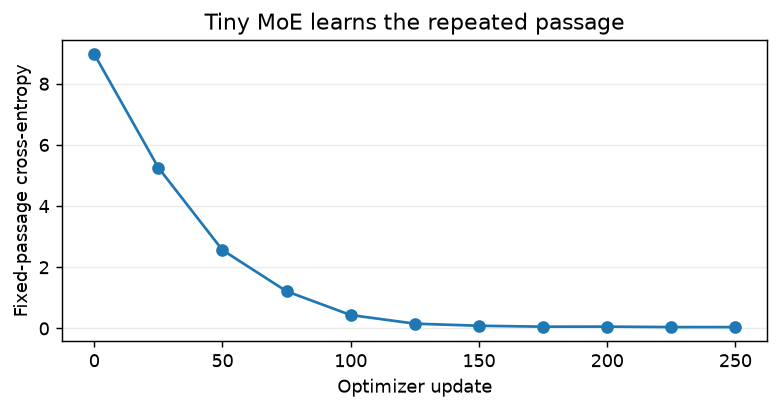

In [13]:
generator = random.Random(7)
history = [(0, initial_ce)]
for step in range(1, training.steps+1):
    x, y = get_batch(corpus, training.batch_size, config.context_length, generator)
    objective, gradients = loss_and_grad(x, y)
    gradients, _ = optim.clip_grad_norm(gradients, training.grad_clip)
    optimizer.learning_rate = learning_rate_at_step(training, step)
    optimizer.update(model, gradients)
    mx.eval(objective, model.parameters(), optimizer.state)
    if step % 25 == 0:
        ce, _ = measure()
        history.append((step, ce))
        print(f"step {step:3d}  objective={objective.item():.4f}  fixed-passage CE={ce:.4f}")
final_ce, final_routing = measure()
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(*zip(*history), marker="o")
ax.set(xlabel="Optimizer update", ylabel="Fixed-passage cross-entropy",
       title="Tiny MoE learns the repeated passage")
ax.grid(axis="y", alpha=.25)
plt.show()
print(f"Cross-entropy before/after: {initial_ce:.4f} → {final_ce:.4f}")

## 7. Inspect expert usage

Each bar counts token assignments to one expert on the same fixed probe.
Four sequences × 32 positions × two selected experts = 256 assignments per
layer. Unequal counts do not establish useful specialization or a defect.
The router entropy and average probabilities give additional context.

blocks.0 mean probabilities [0.248 0.289 0.216 0.247] balance 1.01 entropy 1.157
blocks.1 mean probabilities [0.288 0.241 0.262 0.21 ] balance 0.998 entropy 1.263
Saved weights reload with identical logits.


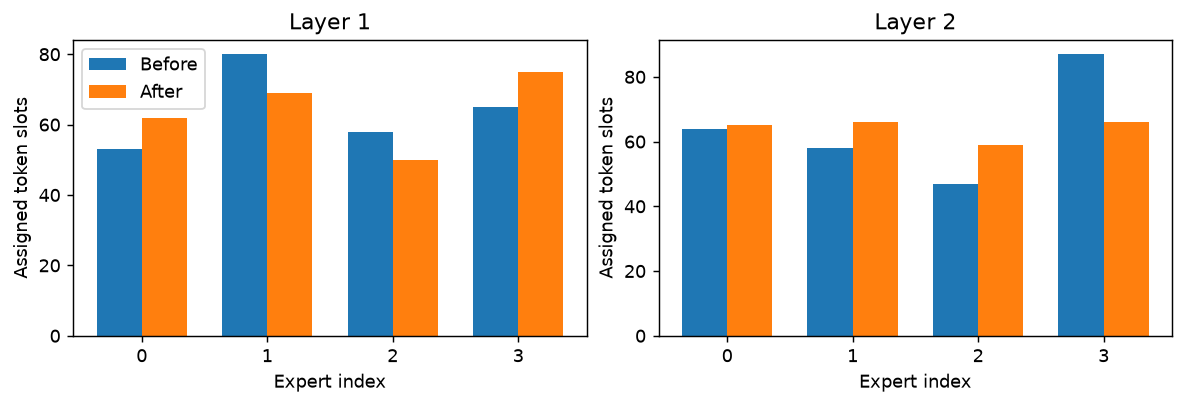

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3), layout="constrained")
for layer, ax in enumerate(axes):
    name = f"blocks.{layer}"
    before = initial_routing[name]["expert_token_counts"]
    after = final_routing[name]["expert_token_counts"]
    ax.bar(np.arange(4)-.18, before, width=.36, label="Before")
    ax.bar(np.arange(4)+.18, after, width=.36, label="After")
    ax.set(title=f"Layer {layer+1}", xlabel="Expert index", ylabel="Assigned token slots",
           xticks=range(4))
    assert after.sum() == 256
    print(name, "mean probabilities", np.round(final_routing[name]["mean_router_probability"], 3),
          "balance", round(float(final_routing[name]["balance_loss"]), 3),
          "entropy", round(float(final_routing[name]["router_entropy"]), 3))
axes[0].legend()
plt.show()
with tempfile.TemporaryDirectory() as temporary:
    checkpoint = Path(temporary) / "moe.safetensors"
    model.save_weights(str(checkpoint))
    restored = GPT(config)
    restored.load_weights(str(checkpoint))
    np.testing.assert_array_equal(np.array(model(probe_x)[0]), np.array(restored(probe_x)[0]))
print("Saved weights reload with identical logits.")

## Run a small corpus experiment

From the repository root:

```sh
DEVELOPER_DIR=/Applications/Xcode.app/Contents/Developer PYTHONPATH=src   .local/venv-mlx-swa/bin/python -m llm_training.pretraining_mlx   --config configs/pretraining/sequential_gpt_mlx_moe_tiny.toml
```

That config trains a width-64, two-layer model for 1,000 updates and 256k
targets on the existing cache. The model has 677,504 parameters. It writes
`metrics.csv`, samples, checkpoints and `statistics.jsonl` under the printed
`gpt-mlx-moe-tiny-*` directory. The latter includes expert counts, mean routing
probabilities, entropy and balance loss on the fixed train probe.
`train_loss` includes the balancing term. Validation and fixed probe losses
are pure cross-entropy.

Try changing only expert count or top-k after recording this baseline.
Increasing expert count changes total capacity. Increasing top-k changes
compute and how outputs mix. This first implementation uses standard
parameterization; the dense μTransfer result has not been validated for its router.

## Sources and implementation choices

- Switch Transformers introduces simple top-1 routing and the auxiliary
  load-balancing loss. We normalize assignment counts across all top-k slots and
  average the balancing term across layers. Our experts use GELU, with no biases.
  [Fedus et al.](https://arxiv.org/abs/2101.03961)
- Mixtral routes each token to two feed-forward experts. We adopt top-2
  selection with normalized gates in a much smaller GPT. It uses gated expert
  FFNs, whereas this teaching version retains our simple GELU FFN.
  [Jiang et al.](https://arxiv.org/abs/2401.04088)
- DeepSeek-V3 uses finer experts, shared experts, sigmoid scores and routing
  bias adjustments, plus a small sequence balancing term. Those are useful
  next comparisons after understanding this router's load and loss.
  [DeepSeek-V3](https://arxiv.org/html/2412.19437v2)